In [2]:
# The purpose of this notebook is to try a log transform of wet strength and see if that helps things

In [3]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
path = project_root / 'data' / 'clean' / 'train_scaled.csv'

df = pd.read_csv(path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]

rng = np.random.RandomState(1)
X = df[formula_cols].fillna(0).to_numpy()
y = df['Wet Strength Mean'].to_numpy()
y = np.log(y)

In [4]:
# break X and y into LOOCV folds, refit the model on each fold/ print
# evaluation metrics

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import r2_score

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

kernel = 1.0 * RBF(length_scale=1e1, length_scale_bounds=(1e-10, 1e4)) + WhiteKernel(
    noise_level=1, noise_level_bounds=(1e-10, 1e1)
)

model = GaussianProcessRegressor(
    kernel=kernel, 
    normalize_y=True, 
    n_restarts_optimizer=10,
    alpha=0,
    random_state = 0
)

# LOOCV cross-validation
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score

loo = LeaveOneOut()

val_predictions = []
val_actuals = []
train_r2_scores = []

fold_num = 1
for train_idx, val_idx in loo.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # Fit model on training fold
    model.fit(X_train, y_train)
    
    # Store validation prediction
    val_pred = model.predict(X_val)
    val_predictions.append(val_pred[0])
    val_actuals.append(y_val[0])
    
    # Evaluate on training fold
    train_pred = model.predict(X_train)
    train_r2 = r2_score(y_train, train_pred)
    train_r2_scores.append(train_r2)
    
    print(f"Fold {fold_num}: Val Prediction = {val_pred[0]:.3f}, Actual = {y_val[0]:.3f}")
    fold_num += 1

# Calculate R² across ALL out-of-fold predictions
val_r2 = r2_score(val_actuals, val_predictions)

# Calculate averages
avg_train_r2 = np.mean(train_r2_scores)

# Create summary table
results_df = pd.DataFrame({
    'Error Source': ['Goal Performance', 'Train Error', 'Validation Error (LOOCV)', 'Test Error'],
    'Value': [
        'R² = .8',
        f'R² = {avg_train_r2:.3f}',
        f'R² = {val_r2:.3f}',
        ''
    ]
})

print("\n" + "="*50)
print("EVALUATION SUMMARY")
print("="*50)
print(results_df.to_string(index=False))

Fold 1: Val Prediction = 3.229, Actual = 3.165
Fold 2: Val Prediction = 2.987, Actual = 3.189
Fold 3: Val Prediction = 3.142, Actual = 3.060
Fold 4: Val Prediction = 3.345, Actual = 3.005
Fold 5: Val Prediction = 3.369, Actual = 3.317
Fold 6: Val Prediction = 3.358, Actual = 3.329
Fold 7: Val Prediction = 4.014, Actual = 3.934
Fold 8: Val Prediction = 4.152, Actual = 4.417
Fold 9: Val Prediction = 4.375, Actual = 4.346
Fold 10: Val Prediction = 4.044, Actual = 4.336
Fold 11: Val Prediction = 3.687, Actual = 3.565
Fold 12: Val Prediction = 3.258, Actual = 2.973
Fold 13: Val Prediction = 3.069, Actual = 2.976
Fold 14: Val Prediction = 3.179, Actual = 2.817
Fold 15: Val Prediction = 3.030, Actual = 2.831
Fold 16: Val Prediction = 3.018, Actual = 2.836
Fold 17: Val Prediction = 2.844, Actual = 2.977
Fold 18: Val Prediction = 3.203, Actual = 3.368
Fold 19: Val Prediction = 3.276, Actual = 3.309
Fold 20: Val Prediction = 3.190, Actual = 3.029
Fold 21: Val Prediction = 2.981, Actual = 3.254
F

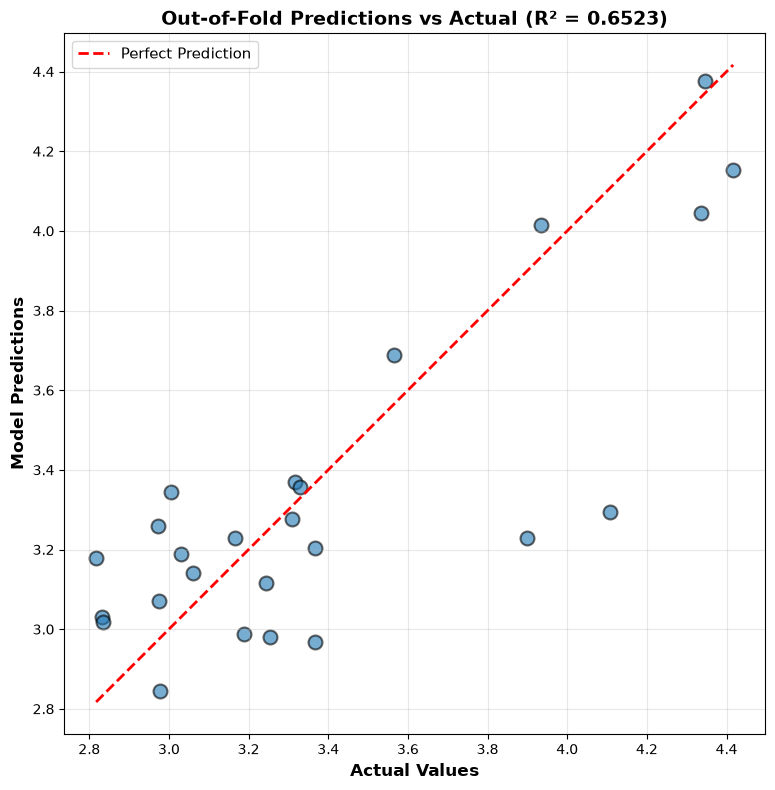

In [5]:
# print out actual vs out of fold prediction and show R^2
import matplotlib.pyplot as plt

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

# Create plot
fig, ax = plt.subplots(figsize=(10, 8))

# Scatter plot
ax.scatter(val_actuals, val_predictions, s=100, alpha=0.6, edgecolors='black', linewidth=1.5)

# Perfect prediction line (y=x)
min_val = min(val_actuals + val_predictions)
max_val = max(val_actuals + val_predictions)
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')

# Labels and title
ax.set_xlabel('Actual Values', fontsize=12, fontweight='bold')
ax.set_ylabel('Model Predictions', fontsize=12, fontweight='bold')
ax.set_title(f'Out-of-Fold Predictions vs Actual (R² = {val_r2:.4f})', 
             fontsize=14, fontweight='bold')

# Grid and legend
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

# Equal aspect ratio for better comparison
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

In [6]:
# Create dataframe with predictions vs actuals
comparison_df = pd.DataFrame({
    'Actual': val_actuals,
    'Prediction': val_predictions,
    'Residual': np.array(val_actuals) - np.array(val_predictions),
    'Abs_Error': np.abs(np.array(val_actuals) - np.array(val_predictions))
})

# Calculate R²
val_r2 = r2_score(val_actuals, val_predictions)

print("\n" + "="*70)
print("OUT-OF-FOLD VALIDATION PREDICTIONS")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70)
print(f"R² Score: {val_r2:.4f}")
print(f"Mean Absolute Error: {comparison_df['Abs_Error'].mean():.4f}")
print(f"RMSE: {np.sqrt(np.mean(comparison_df['Residual']**2)):.4f}")
print("="*70)


OUT-OF-FOLD VALIDATION PREDICTIONS
  Actual  Prediction  Residual  Abs_Error
3.164631    3.229242 -0.064611   0.064611
3.188766    2.986634  0.202132   0.202132
3.060089    3.142130 -0.082042   0.082042
3.004870    3.345325 -0.340455   0.340455
3.317285    3.369093 -0.051808   0.051808
3.329411    3.358125 -0.028713   0.028713
3.934444    4.014017 -0.079573   0.079573
4.416579    4.152024  0.264555   0.264555
4.345549    4.375390 -0.029841   0.029841
4.336067    4.043977  0.292090   0.292090
3.565298    3.687434 -0.122137   0.122137
2.973487    3.258399 -0.284912   0.284912
2.976040    3.069491 -0.093452   0.093452
2.817204    3.179422 -0.362218   0.362218
2.831447    3.029632 -0.198185   0.198185
2.835564    3.017509 -0.181946   0.181946
2.976549    2.844181  0.132369   0.132369
3.367584    3.203132  0.164452   0.164452
3.309080    3.276069  0.033011   0.033011
3.029260    3.189722 -0.160462   0.160462
3.253742    2.980792  0.272950   0.272950
3.366561    2.968113  0.398448   0.39844

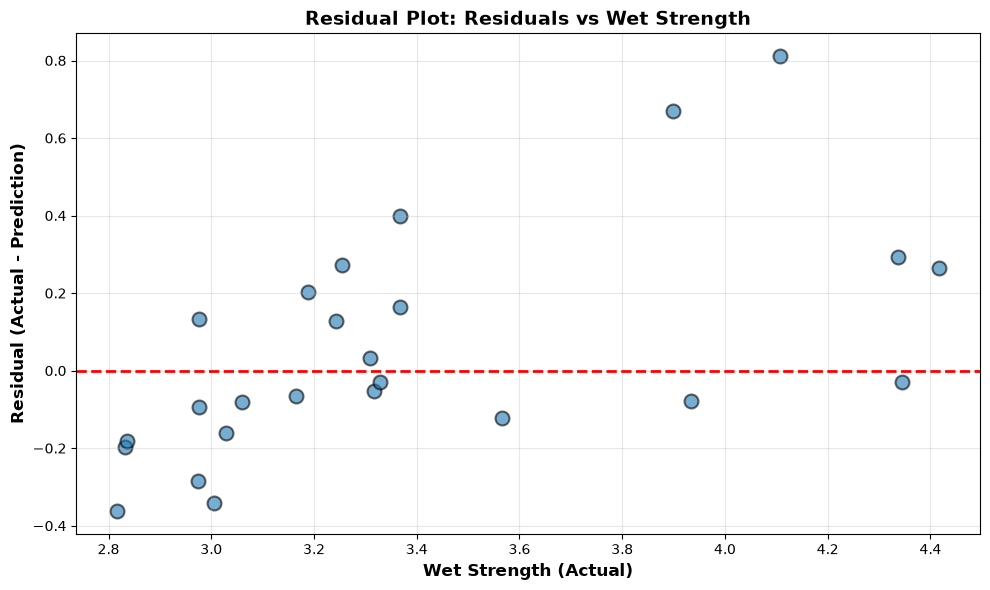

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(comparison_df['Actual'], comparison_df['Residual'], s=100, alpha=0.6, edgecolors='black', linewidth=1.5)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.xlabel('Wet Strength (Actual)', fontsize=12, fontweight='bold')
plt.ylabel('Residual (Actual - Prediction)', fontsize=12, fontweight='bold')
plt.title('Residual Plot: Residuals vs Wet Strength', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()